In [135]:
import scipy as sp
#from scipy.misc import derivative
from scipy.special import jv, hankel2, hankel1, yv, jvp, yvp, factorial
from scipy.optimize import minimize
import numpy as np
import matplotlib.pyplot as plt
from numpy import sqrt, linspace, zeros, ones, pi, exp, conj, argmin, unravel_index, log, einsum, tan, log10, atan, cosh
import torch
import warnings
warnings.filterwarnings("ignore")
from utils import h_z_cpa, h_z_cpa_denominator, h_z_cpa_numerator, e_z_cpa, e_z_cpa_numerator, hl2_prime, hl1_prime, hbar, c, alpha, graphene_conductivity
plt.rc('font', size=14)          # controls default text sizes

### In this notebook, we re-produce some of the figures of the following paper: [Self-consistent multimode lasing theory for complex or random lasing media](https://journals.aps.org/pra/pdf/10.1103/PhysRevA.74.043822?casa_token=hjAL2eDIFCMAAAAA%3A8Rq65VMyIWZsy_5yMTCO9tiBT2oXJnqNovmy7C0t-0IX18L9AVcAmKxCZ63-J6XEZQ9aBLaiS1nKxps)

In [51]:
def constant_flux(l, n, k, k_m):
    return n*k_m*jvp(l, n*k_m)*hankel1(l, k)-k*hl1_prime(l, k)*jv(l, n*k_m) 

In [91]:
l = 40
n = 1.3
N_real = 1000
N_imag = 200
k_m_real = linspace(71.19, 71.2, N_real)
k_m_imag = linspace(-0.76, -0.74, N_imag)
k_m = k_m_real.reshape((N_real, 1)).repeat(N_imag, axis=1)+1j*k_m_imag.reshape((1, N_imag)).repeat(N_real, axis=0)
cf_arr = constant_flux(l, n, k_m.real, k_m)

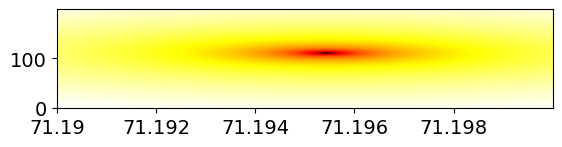

In [92]:
plt.imshow(np.log(np.abs(cf_arr)**2).T, origin="lower", cmap="hot")
xticks = [0, 200, 400, 600, 800]
plt.xticks(xticks, k_m_real[xticks].round(3));

In [79]:
k_m_guess = k_m.flatten()[(np.abs(cf_arr)**2).argmin()]

In [137]:
k_m_guess

np.complex128(71.19541541541541-0.7489447236180905j)

In [126]:
k_m_guess_real = k_m_guess.real
k_m_guess_imag = k_m_guess.imag

N_real = 200
N_imag = 200
tolerance = 3e-2
k = linspace(k_m_guess_real-tolerance, k_m_guess_real+tolerance, N_real)
k_m_real = linspace(k_m_guess_real-tolerance, k_m_guess_real+tolerance, N_real)
k_m_imag = linspace(k_m_guess_imag-tolerance, k_m_guess_imag+tolerance, N_imag)
k_m = k_m_real.reshape((N_real, 1, 1)).repeat(N_imag, axis=1).repeat(N_real, axis=2)+1j*k_m_imag.reshape((1, N_imag, 1)).repeat(N_real, axis=0).repeat(N_real, axis=2)
k = k_m_real.reshape((1, 1, N_real)).repeat(N_real, axis=0).repeat(N_imag, axis=1);

In [127]:
cf_arr = constant_flux(l, n, k, k_m)

In [118]:
#k_m_guess_prime = 71.19539070-0.74853902j
cf_arr = constant_flux(l, n, k, k_m_guess_prime)

In [133]:
k.flatten()[(np.abs(cf_arr)**2).argmin()]

np.float64(71.22451089280234)

In [134]:
k_m.flatten()[(np.abs(cf_arr)**2).argmin()]

np.complex128(71.19556616918426-0.7496984924623116j)